# Подготовка данных для модели уровня жизни Башкортостана

Проверка стационарности (ADF), поиск ложных корреляций, отбор признаков по мультиколлинеарности. Итоговая модель ARIMAX оценивалась в gretl (`gretl/model_search.inp`).


In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error
from scipy.stats import pearsonr
import statsmodels.api as sm
from itertools import combinations
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, normal_ad
import warnings

In [92]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [93]:
df = pd.read_excel('../data/indicators_raw.xlsx', index_col='Год')
df.head()

,"Среднедушевые доходы с учетом ИПЦ, руб","ВРП на душу населения с учетом ИПЦ, руб","Инвестиции в основной капитал с учетом ИПЦ, руб","Уровень безработицы, %","Средняя продолжительность жизни, лет","Число врачей на 10000 человек населения, чел","Протяженность автомобильных дорог общего пользования с твердым покрытием, км",Коэффициент Джини,"Миграционный прирост (убыль) на 1000 человек населения, чел","Естественный прирост (убыль) на 1000 человек населения, чел","Число студентов на 10000 человек населения, чел","Число зарегистрированных преступлений на 100 000 человек населения, чел."
Год,,,,,,,,,,,,
1998,8368.959519,187970.252597,1.529088e+11,13.3,68.0,40.9,21517,0.362,2.528448,-0.971453,175.832930,954.0
1999,10771.901013,234437.074270,1.504950e+11,12.1,67.0,41.2,21751,0.343,2.598178,-2.742845,210.689328,1127.0
2000,12372.675522,276032.668327,2.526711e+11,11.6,66.7,41.0,21869,0.347,0.969576,-2.893663,246.889580,1170.0
2001,14581.790750,273355.524303,2.852010e+11,10.7,66.6,40.6,21952,0.364,0.270185,-2.969598,287.223426,1443.0
2002,16616.740125,277460.178920,2.756259e+11,8.3,66.1,40.8,22037,0.370,0.474124,-2.998318,349.194354,1339.0


In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26 entries, 1998 to 2023
Data columns (total 12 columns):
 #   Column                                                                        Non-Null Count  Dtype  
---  ------                                                                        --------------  -----  
 0   Среднедушевые доходы с учетом ИПЦ, руб                                        26 non-null     float64
 1   ВРП на душу населения с учетом ИПЦ, руб                                       26 non-null     float64
 2   Инвестиции в основной капитал с учетом ИПЦ, руб                               26 non-null     float64
 3   Уровень безработицы, %                                                        26 non-null     float64
 4   Средняя продолжительность жизни, лет                                          26 non-null     float64
 5   Число врачей на 10000 человек населения, чел                                  26 non-null     float64
 6   Протяженность автомобильных дорог об

# Приведение рядов к стационарности

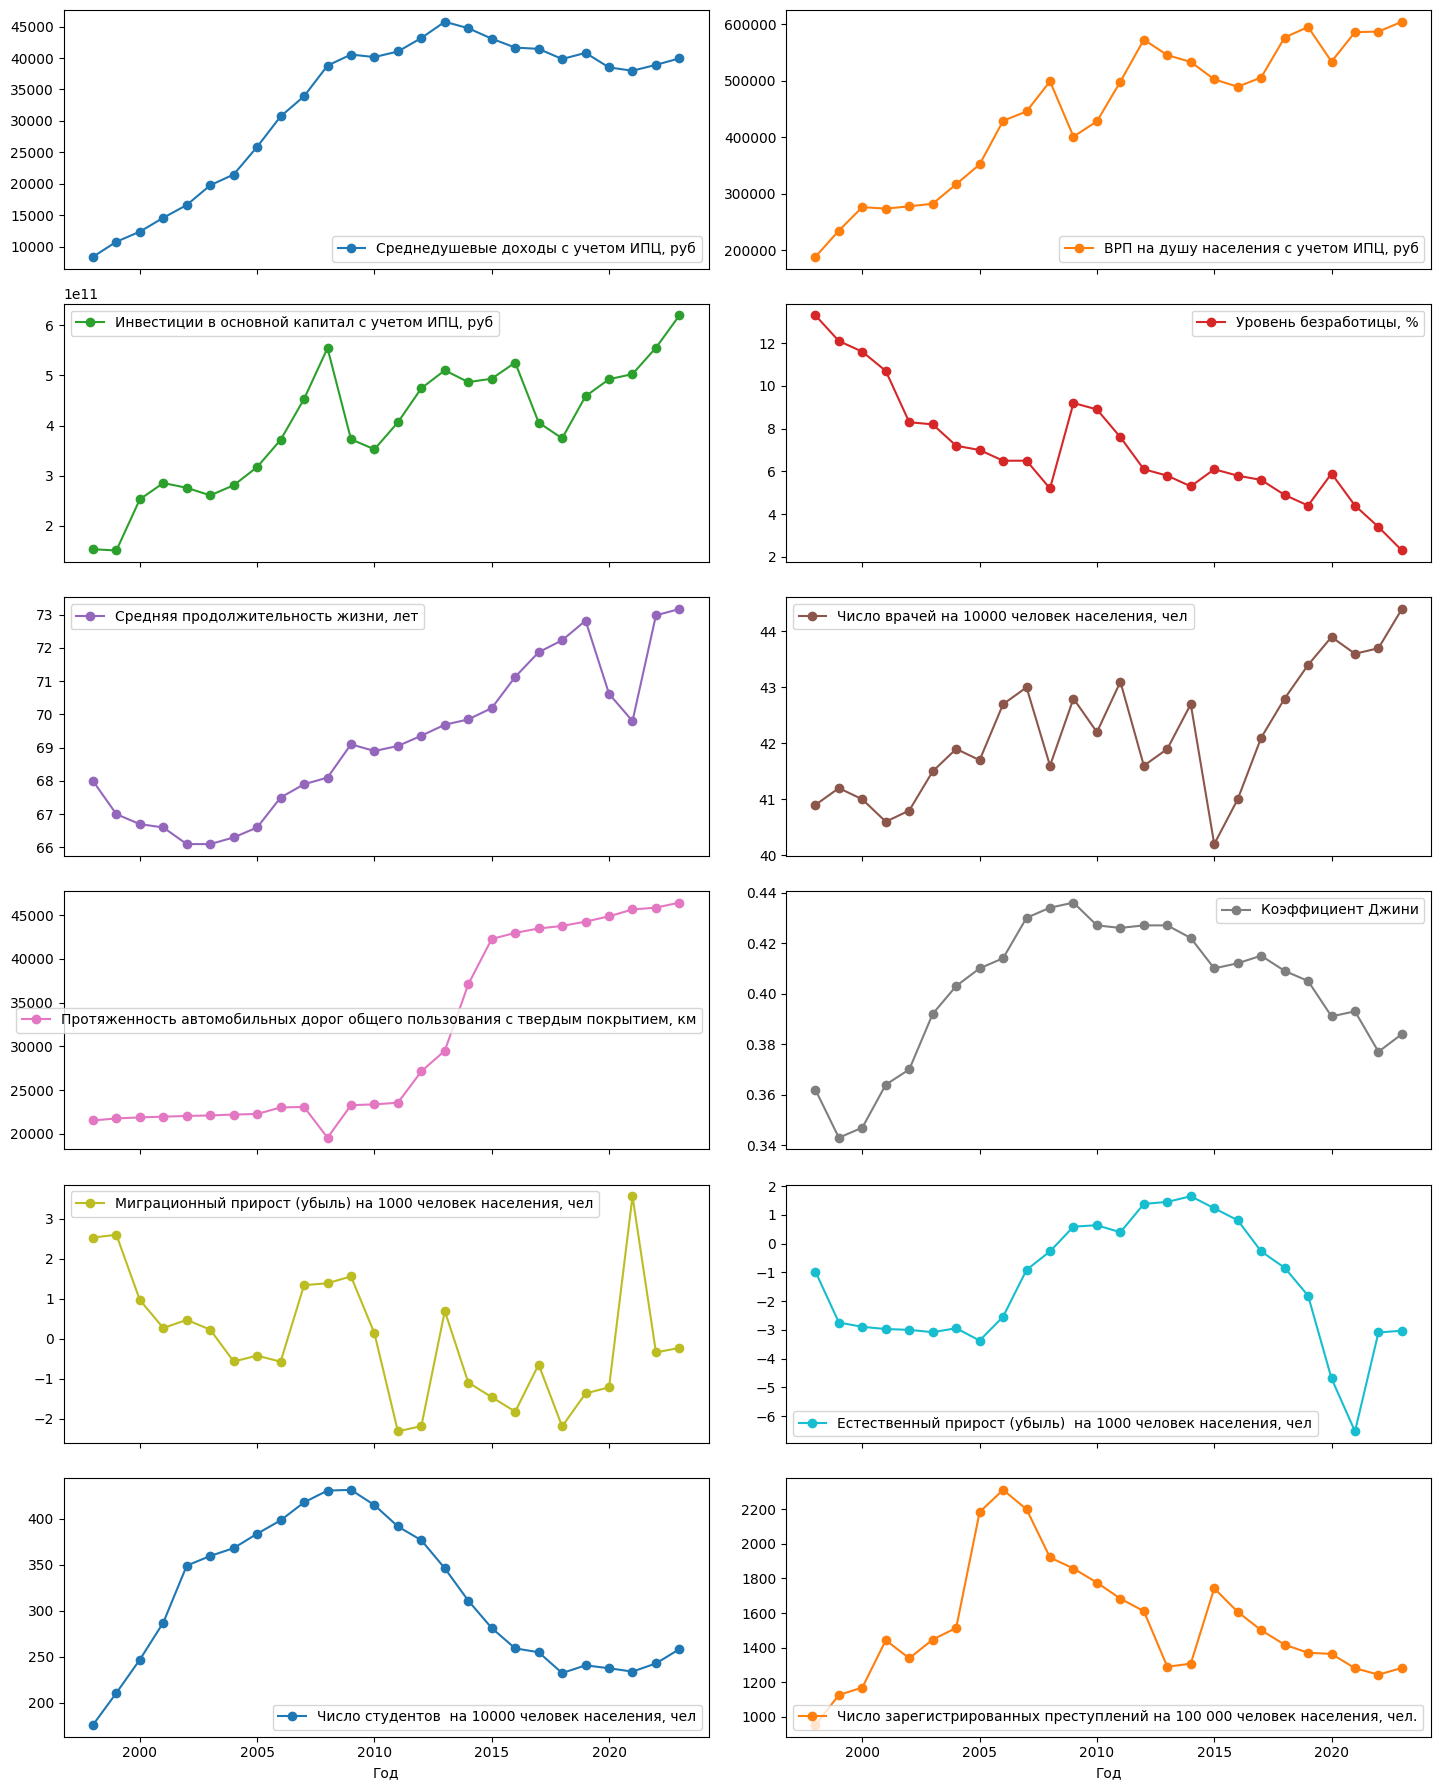

In [95]:
import math
import matplotlib.pyplot as plt

n_cols = 2
n_rows = math.ceil(len(df.columns) / n_cols)

df.plot(subplots=True, layout=(n_rows, n_cols), figsize=(16, n_rows * 3), style='-o')
plt.tight_layout()
plt.show()

In [96]:
# ADF-тест
def adf_test(series):
    result = adfuller(series.dropna())
    return result[1]  # p-value

In [97]:
# Функция, делающая ряд стационарным поэтапно
def make_stationary(series, name=''):
    transformed = series.copy()
    steps = []

    # 1. Попытка обычного ADF
    p_val = adf_test(transformed)
    if p_val <= 0.05:
        return transformed, f'{name}: уже стационарен'

    # 2. Логарифмирование (если все значения > 0)
    if (transformed > 0).all():
        transformed = np.log(transformed)
        steps.append('log')
        p_val = adf_test(transformed)
        if p_val <= 0.05:
            return transformed, f'{name}: log'
    
    # 3. Первые разности
    transformed = transformed.diff().dropna()
    steps.append('diff1')
    p_val = adf_test(transformed)
    if p_val <= 0.05:
        return transformed, f'{name}: {" → ".join(steps)}'
    
    # 4. Повторные разности
    for i in range(2, 5):
        transformed = transformed.diff().dropna()
        steps.append(f'diff{i}')
        p_val = adf_test(transformed)
        if p_val <= 0.05:
            return transformed, f'{name}: {" → ".join(steps)}'
    
    return transformed, f'{name}: Не удалось сделать стационарным (после {len(steps)} шагов)'

In [98]:
# Обработка всех столбцов
stationary_df = pd.DataFrame()
info = []
for col in df.columns:
    transformed, steps = make_stationary(df[col], name=col)
    stationary_df[col] = transformed
    info.append(steps)

# Печать итогов
print("\n".join(info))

Среднедушевые доходы с учетом ИПЦ, руб: log → diff1 → diff2
ВРП на душу населения с учетом ИПЦ, руб: log
Инвестиции в основной капитал с учетом ИПЦ, руб: log → diff1 → diff2
Уровень безработицы, %: log → diff1
Средняя продолжительность жизни, лет: log → diff1
Число врачей на 10000 человек населения, чел: log → diff1
Протяженность автомобильных дорог общего пользования с твердым покрытием, км: log → diff1
Коэффициент Джини: log → diff1 → diff2
Миграционный прирост (убыль) на 1000 человек населения, чел: diff1 → diff2 → diff3
Естественный прирост (убыль)  на 1000 человек населения, чел: diff1
Число студентов  на 10000 человек населения, чел: log → diff1 → diff2
Число зарегистрированных преступлений на 100 000 человек населения, чел.: log → diff1


In [99]:
transformations = {
    "Среднедушевые доходы с учетом ИПЦ, руб": ["log", "diff1", "diff2"],
    "ВРП на душу населения с учетом ИПЦ, руб": ["log"],
    "Инвестиции в основной капитал с учетом ИПЦ, руб": ["log", "diff1", "diff2"],
    "Уровень безработицы, %": ["log", "diff1"],
    "Средняя продолжительность жизни, лет": ["log", "diff1"],
    "Число врачей на 10000 человек населения, чел": ["log", "diff1"],
    "Протяженность автомобильных дорог общего пользования с твердым покрытием, км": ["log", "diff1"],
    "Коэффициент Джини": ["log", "diff1", "diff2"],
    "Миграционный прирост (убыль) на 1000 человек населения, чел": ["diff1", "diff2", "diff3"],
    "Естественный прирост (убыль)  на 1000 человек населения, чел": ["diff1"],
    "Число студентов  на 10000 человек населения, чел": ["log", "diff1", "diff2"],
    'Число зарегистрированных преступлений на 100 000 человек населения, чел.': ["log", "diff1"]
}

In [100]:
# Применение преобразований
stationary_df = pd.DataFrame(index=df.index)
p_values = {}

for col, steps in transformations.items():
    transformed = df[col].copy()
    for step in steps:
        if step == 'log':
            if (transformed <= 0).any():
                raise ValueError(f'Невозможно логарифмировать {col}: есть значения ≤ 0')
            transformed = np.log(transformed)
        elif 'diff' in step:
            transformed = transformed.diff().dropna()
    transformed = transformed.dropna()
    stationary_df[col] = transformed
    p_values[col] = adf_test(transformed)

In [101]:
# Вывод p-value по каждому ряду
print("📊 p-value после всех преобразований:\n")
for col, p in p_values.items():
    status = " ряд стационарен" if p <= 0.05 else "ряд нестационарен"
    print(f"{col}: p-value = {p:.5f} → {status}")

📊 p-value после всех преобразований:

Среднедушевые доходы с учетом ИПЦ, руб: p-value = 0.00000 →  ряд стационарен
ВРП на душу населения с учетом ИПЦ, руб: p-value = 0.02596 →  ряд стационарен
Инвестиции в основной капитал с учетом ИПЦ, руб: p-value = 0.00071 →  ряд стационарен
Уровень безработицы, %: p-value = 0.00003 →  ряд стационарен
Средняя продолжительность жизни, лет: p-value = 0.02657 →  ряд стационарен
Число врачей на 10000 человек населения, чел: p-value = 0.00000 →  ряд стационарен
Протяженность автомобильных дорог общего пользования с твердым покрытием, км: p-value = 0.00052 →  ряд стационарен
Коэффициент Джини: p-value = 0.04690 →  ряд стационарен
Миграционный прирост (убыль) на 1000 человек населения, чел: p-value = 0.00002 →  ряд стационарен
Естественный прирост (убыль)  на 1000 человек населения, чел: p-value = 0.00102 →  ряд стационарен
Число студентов  на 10000 человек населения, чел: p-value = 0.00000 →  ряд стационарен
Число зарегистрированных преступлений на 100 00

In [102]:
stationary_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26 entries, 1998 to 2023
Data columns (total 12 columns):
 #   Column                                                                        Non-Null Count  Dtype  
---  ------                                                                        --------------  -----  
 0   Среднедушевые доходы с учетом ИПЦ, руб                                        24 non-null     float64
 1   ВРП на душу населения с учетом ИПЦ, руб                                       26 non-null     float64
 2   Инвестиции в основной капитал с учетом ИПЦ, руб                               24 non-null     float64
 3   Уровень безработицы, %                                                        25 non-null     float64
 4   Средняя продолжительность жизни, лет                                          25 non-null     float64
 5   Число врачей на 10000 человек населения, чел                                  25 non-null     float64
 6   Протяженность автомобильных дорог об

# Ложная корреляция

In [103]:
def analyze_false_correlation(df, features, target=None):
    results = []

    if target:
        pairs = [(target, var) for var in features if var != target]
    else:
        pairs = list(combinations(features, 2))

    for var1, var2 in pairs:
        series1 = df[var1].dropna()
        series2 = df[var2].dropna()
        common_index = series1.index.intersection(series2.index)

        s1 = series1.loc[common_index]
        s2 = series2.loc[common_index]

        # Исходная корреляция
        corr_raw, _ = pearsonr(s1, s2)

        # Корреляция разностей
        diff1 = s1.diff().dropna()
        diff2 = s2.diff().dropna()
        idx_diff = diff1.index.intersection(diff2.index)
        corr_diff, _ = pearsonr(diff1.loc[idx_diff], diff2.loc[idx_diff])

        # Корреляция остатков от тренда
        t = np.arange(len(s1))
        t_const = sm.add_constant(t)

        model1 = sm.OLS(s1.values, t_const).fit()
        model2 = sm.OLS(s2.values, t_const).fit()

        resid1 = model1.resid
        resid2 = model2.resid

        corr_detrended, _ = pearsonr(resid1, resid2)

        # Регрессия с временем
        df_tmp = pd.DataFrame({'y': s1.values, 'x': s2.values, 't': np.arange(len(s1))})
        X = sm.add_constant(df_tmp[['x', 't']])
        y = df_tmp['y']
        model = sm.OLS(y, X).fit()
        pval_x = model.pvalues['x']

        results.append({
            'var1': var1,
            'var2': var2,
            'corr_raw': corr_raw,
            'corr_diff': corr_diff,
            'corr_detrended': corr_detrended,
            'reg_pval_x': pval_x
        })

    return pd.DataFrame(results)

In [104]:
df_results = analyze_false_correlation(stationary_df, features=[
    'ВРП на душу населения с учетом ИПЦ, руб',
    'Инвестиции в основной капитал с учетом ИПЦ, руб',
    'Уровень безработицы, %', 
    'Средняя продолжительность жизни, лет',
    'Число врачей на 10000 человек населения, чел',
    'Протяженность автомобильных дорог общего пользования с твердым покрытием, км',
    'Коэффициент Джини',
    'Миграционный прирост (убыль) на 1000 человек населения, чел',
    'Естественный прирост (убыль)  на 1000 человек населения, чел',
    'Число студентов  на 10000 человек населения, чел',
    'Число зарегистрированных преступлений на 100 000 человек населения, чел.'
])

In [105]:
df_results.head()

,var1,var2,corr_raw,corr_diff,corr_detrended,reg_pval_x
0,"ВРП на душу населения с учетом ИПЦ, руб","Инвестиции в основной капитал с учетом ИПЦ, руб",0.059160,0.376673,0.148286,0.499520
1,"ВРП на душу населения с учетом ИПЦ, руб","Уровень безработицы, %",-0.142548,-0.615322,-0.065961,0.759434
2,"ВРП на душу населения с учетом ИПЦ, руб","Средняя продолжительность жизни, лет",0.297429,0.096284,0.215267,0.312401
3,"ВРП на душу населения с учетом ИПЦ, руб","Число врачей на 10000 человек населения, чел",-0.032850,-0.312821,-0.247321,0.243957
4,"ВРП на душу населения с учетом ИПЦ, руб",Протяженность автомобильных дорог общего польз...,0.171777,-0.325582,0.092278,0.668032


In [106]:
# Пороговые значения для определения ложной корреляции
THRESH_RAW = 0.7
THRESH_DIFF = 0.3
THRESH_DETREND = 0.4
THRESH_PVAL = 0.05

# Фильтрация пар с подозрением на ложную корреляцию
false_corr = df_results[
    (df_results['corr_raw'].abs() > THRESH_RAW) &
    (df_results['corr_diff'].abs() < THRESH_DIFF) &
    (df_results['corr_detrended'].abs() < THRESH_DETREND) &
    (df_results['reg_pval_x'] > THRESH_PVAL)
]

# Соберем все подозрительные переменные
to_consider = pd.concat([false_corr['var1'], false_corr['var2']])
to_consider = to_consider.value_counts()

# Ограничим только теми, кто чаще всего встречается в ложных парах
# Например, в >2 ложных парах
suspect_features = to_consider[to_consider > 2].index.tolist()

print("Признаки с высокой вероятностью ложной корреляции (рекомендуются к исключению):")
for feat in suspect_features:
    print("-", feat)

# Все уникальные признаки в исходной таблице
all_features = pd.unique(df_results[['var1', 'var2']].values.ravel('K'))

# Оставшиеся признаки
kept_features = [f for f in all_features if f not in suspect_features]

print("\nРекомендуется оставить в модели:")
for feat in kept_features:
    print("-", feat)


Признаки с высокой вероятностью ложной корреляции (рекомендуются к исключению):

Рекомендуется оставить в модели:
- ВРП на душу населения с учетом ИПЦ, руб
- Инвестиции в основной капитал с учетом ИПЦ, руб
- Уровень безработицы, %
- Средняя продолжительность жизни, лет
- Число врачей на 10000 человек населения, чел
- Протяженность автомобильных дорог общего пользования с твердым покрытием, км
- Коэффициент Джини
- Миграционный прирост (убыль) на 1000 человек населения, чел
- Естественный прирост (убыль)  на 1000 человек населения, чел
- Число студентов  на 10000 человек населения, чел
- Число зарегистрированных преступлений на 100 000 человек населения, чел.


In [107]:
df.columns


Index(['Среднедушевые доходы с учетом ИПЦ, руб',
       'ВРП на душу населения с учетом ИПЦ, руб',
       'Инвестиции в основной капитал с учетом ИПЦ, руб',
       'Уровень безработицы, %', 'Средняя продолжительность жизни, лет',
       'Число врачей на 10000 человек населения, чел',
       'Протяженность автомобильных дорог общего пользования с твердым покрытием, км',
       'Коэффициент Джини',
       'Миграционный прирост (убыль) на 1000 человек населения, чел',
       'Естественный прирост (убыль)  на 1000 человек населения, чел',
       'Число студентов  на 10000 человек населения, чел',
       'Число зарегистрированных преступлений на 100 000 человек населения, чел.'],
      dtype='object')

# Мультиколлинеарность и отбор признаков

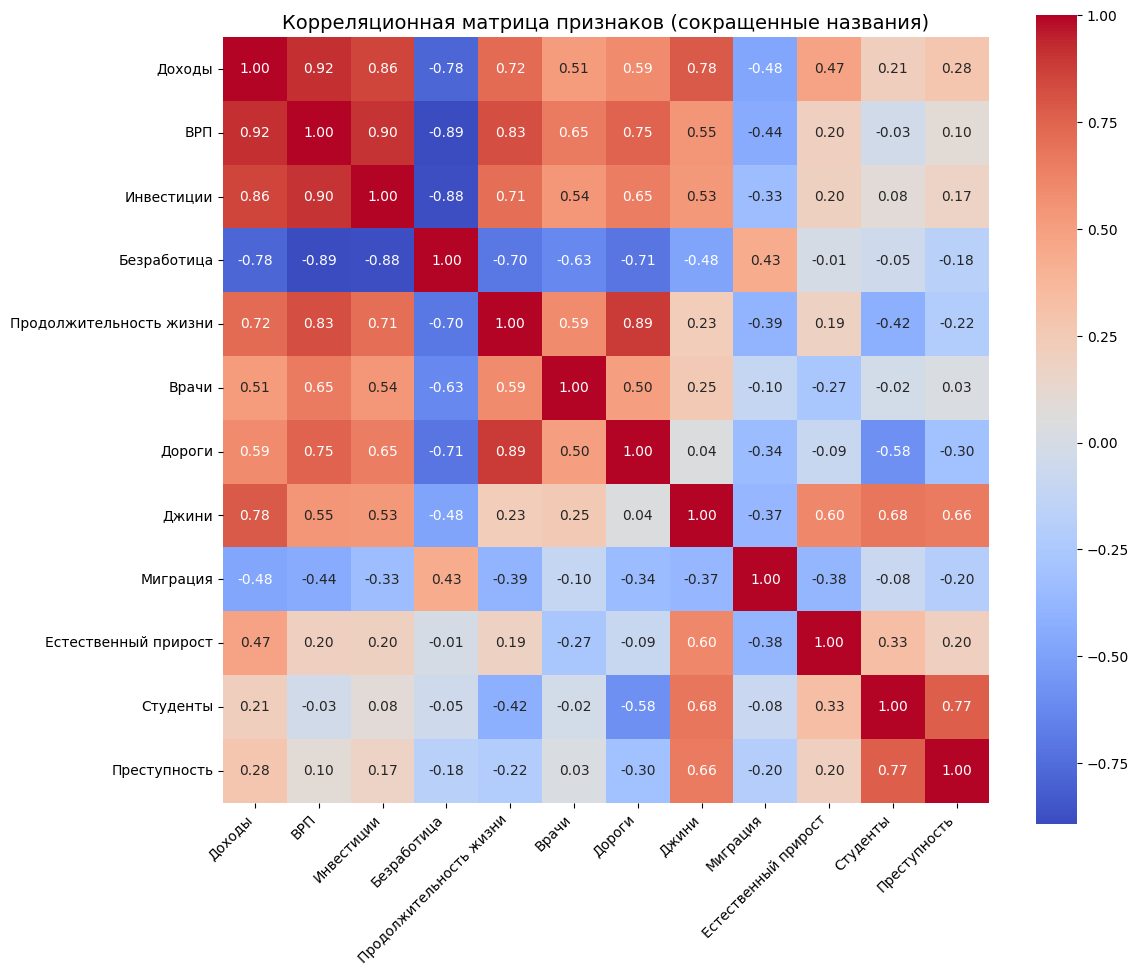

In [108]:
df1 = df.copy()

rename_columns = {
    'Среднедушевые доходы с учетом ИПЦ, руб': 'Доходы',
    'ВРП на душу населения с учетом ИПЦ, руб': 'ВРП',
    'Инвестиции в основной капитал с учетом ИПЦ, руб': 'Инвестиции',
    'Уровень безработицы, %': 'Безработица',
    'Средняя продолжительность жизни, лет': 'Продолжительность жизни',
    'Число врачей на 10000 человек населения, чел': 'Врачи',
    'Протяженность автомобильных дорог общего пользования с твердым покрытием, км': 'Дороги',
    'Коэффициент Джини': 'Джини',
    'Миграционный прирост (убыль) на 1000 человек населения, чел': 'Миграция',
    'Естественный прирост (убыль)  на 1000 человек населения, чел': 'Естественный прирост',
    'Число студентов  на 10000 человек населения, чел': 'Студенты',
    'Число зарегистрированных преступлений на 100 000 человек населения, чел.': 'Преступность'
}

# Переименование колонок
df1.rename(columns=rename_columns, inplace=True)

# Построение корреляционной матрицы
plt.figure(figsize=(12, 10))
sns.heatmap(df1.corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True)
plt.title('Корреляционная матрица признаков (сокращенные названия)', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [109]:
def competitive_feature_selection(df, target_col, threshold=0.7):
    corr = df.corr()
    predictors = [col for col in df.columns if col != target_col]
    to_drop = set()
    
    # Сортировка по корреляции с таргетом
    sorted_by_target_corr = sorted(
        predictors, 
        key=lambda x: abs(corr.loc[target_col, x]), 
        reverse=True
    )

    selected = []
    for i, xi in enumerate(sorted_by_target_corr):
        if xi in to_drop:
            continue
        selected.append(xi)
        for xj in sorted_by_target_corr[i+1:]:
            if abs(corr.loc[xi, xj]) > threshold:
                to_drop.add(xj)

    return selected

In [110]:
selected_features = competitive_feature_selection(df, target_col='Среднедушевые доходы с учетом ИПЦ, руб', threshold=0.7)
print("Выбранные признаки:", *selected_features, sep='\n')

Выбранные признаки:
ВРП на душу населения с учетом ИПЦ, руб
Коэффициент Джини
Число врачей на 10000 человек населения, чел
Миграционный прирост (убыль) на 1000 человек населения, чел
Естественный прирост (убыль)  на 1000 человек населения, чел
Число зарегистрированных преступлений на 100 000 человек населения, чел.


In [111]:
selected_features.append('Среднедушевые доходы с учетом ИПЦ, руб')

In [112]:
df = df[selected_features]
df.head()

,"ВРП на душу населения с учетом ИПЦ, руб",Коэффициент Джини,"Число врачей на 10000 человек населения, чел","Миграционный прирост (убыль) на 1000 человек населения, чел","Естественный прирост (убыль) на 1000 человек населения, чел","Число зарегистрированных преступлений на 100 000 человек населения, чел.","Среднедушевые доходы с учетом ИПЦ, руб"
Год,,,,,,,
1998,187970.252597,0.362,40.9,2.528448,-0.971453,954.0,8368.959519
1999,234437.074270,0.343,41.2,2.598178,-2.742845,1127.0,10771.901013
2000,276032.668327,0.347,41.0,0.969576,-2.893663,1170.0,12372.675522
2001,273355.524303,0.364,40.6,0.270185,-2.969598,1443.0,14581.790750
2002,277460.178920,0.370,40.8,0.474124,-2.998318,1339.0,16616.740125


In [113]:
df.rename(columns={
    'ВРП на душу населения с учетом ИПЦ, руб': 'ВРП c ИПЦ',
    'Коэффициент Джини': 'Джини',
    'Число врачей на 10000 человек населения, чел': 'Врачи на 10000',
    'Миграционный прирост (убыль) на 1000 человек населения, чел': 'Миграция на 1000',
    'Естественный прирост (убыль)  на 1000 человек населения, чел': 'Естественный прирост',
    'Число зарегистрированных преступлений на 100 000 человек населения, чел.': 'Преступления на 100000',
    'Среднедушевые доходы с учетом ИПЦ, руб': 'Доходы ИПЦ'
}, inplace=True)

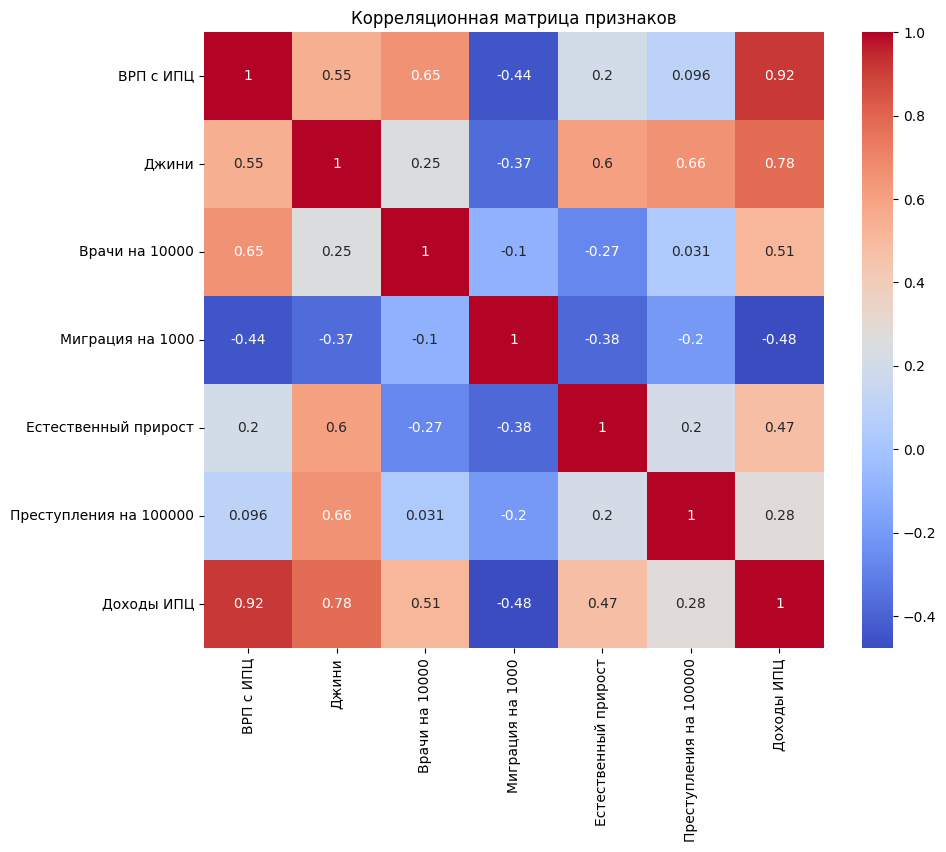

In [114]:
# 1. Матрица корреляции
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Корреляционная матрица признаков')
plt.show()

In [115]:
df['Доходы ИПЦ log']  = np.log(df['Доходы ИПЦ'])

In [116]:
df = df.drop(columns=['Доходы ИПЦ'])

In [117]:
df.to_excel("../data/selected_features.xlsx")

In [118]:
df = pd.read_excel('../data/selected_features.xlsx', index_col='Год')
df.head()

,ВРП c ИПЦ,Джини,Врачи на 10000,Миграция на 1000,Естественный прирост,Преступления на 100000,Доходы ИПЦ log
Год,,,,,,,
1998,187970.252597,0.362,40.9,2.528448,-0.971453,954.0,9.032285
1999,234437.074270,0.343,41.2,2.598178,-2.742845,1127.0,9.284696
2000,276032.668327,0.347,41.0,0.969576,-2.893663,1170.0,9.423246
2001,273355.524303,0.364,40.6,0.270185,-2.969598,1443.0,9.587529
2002,277460.178920,0.370,40.8,0.474124,-2.998318,1339.0,9.718166


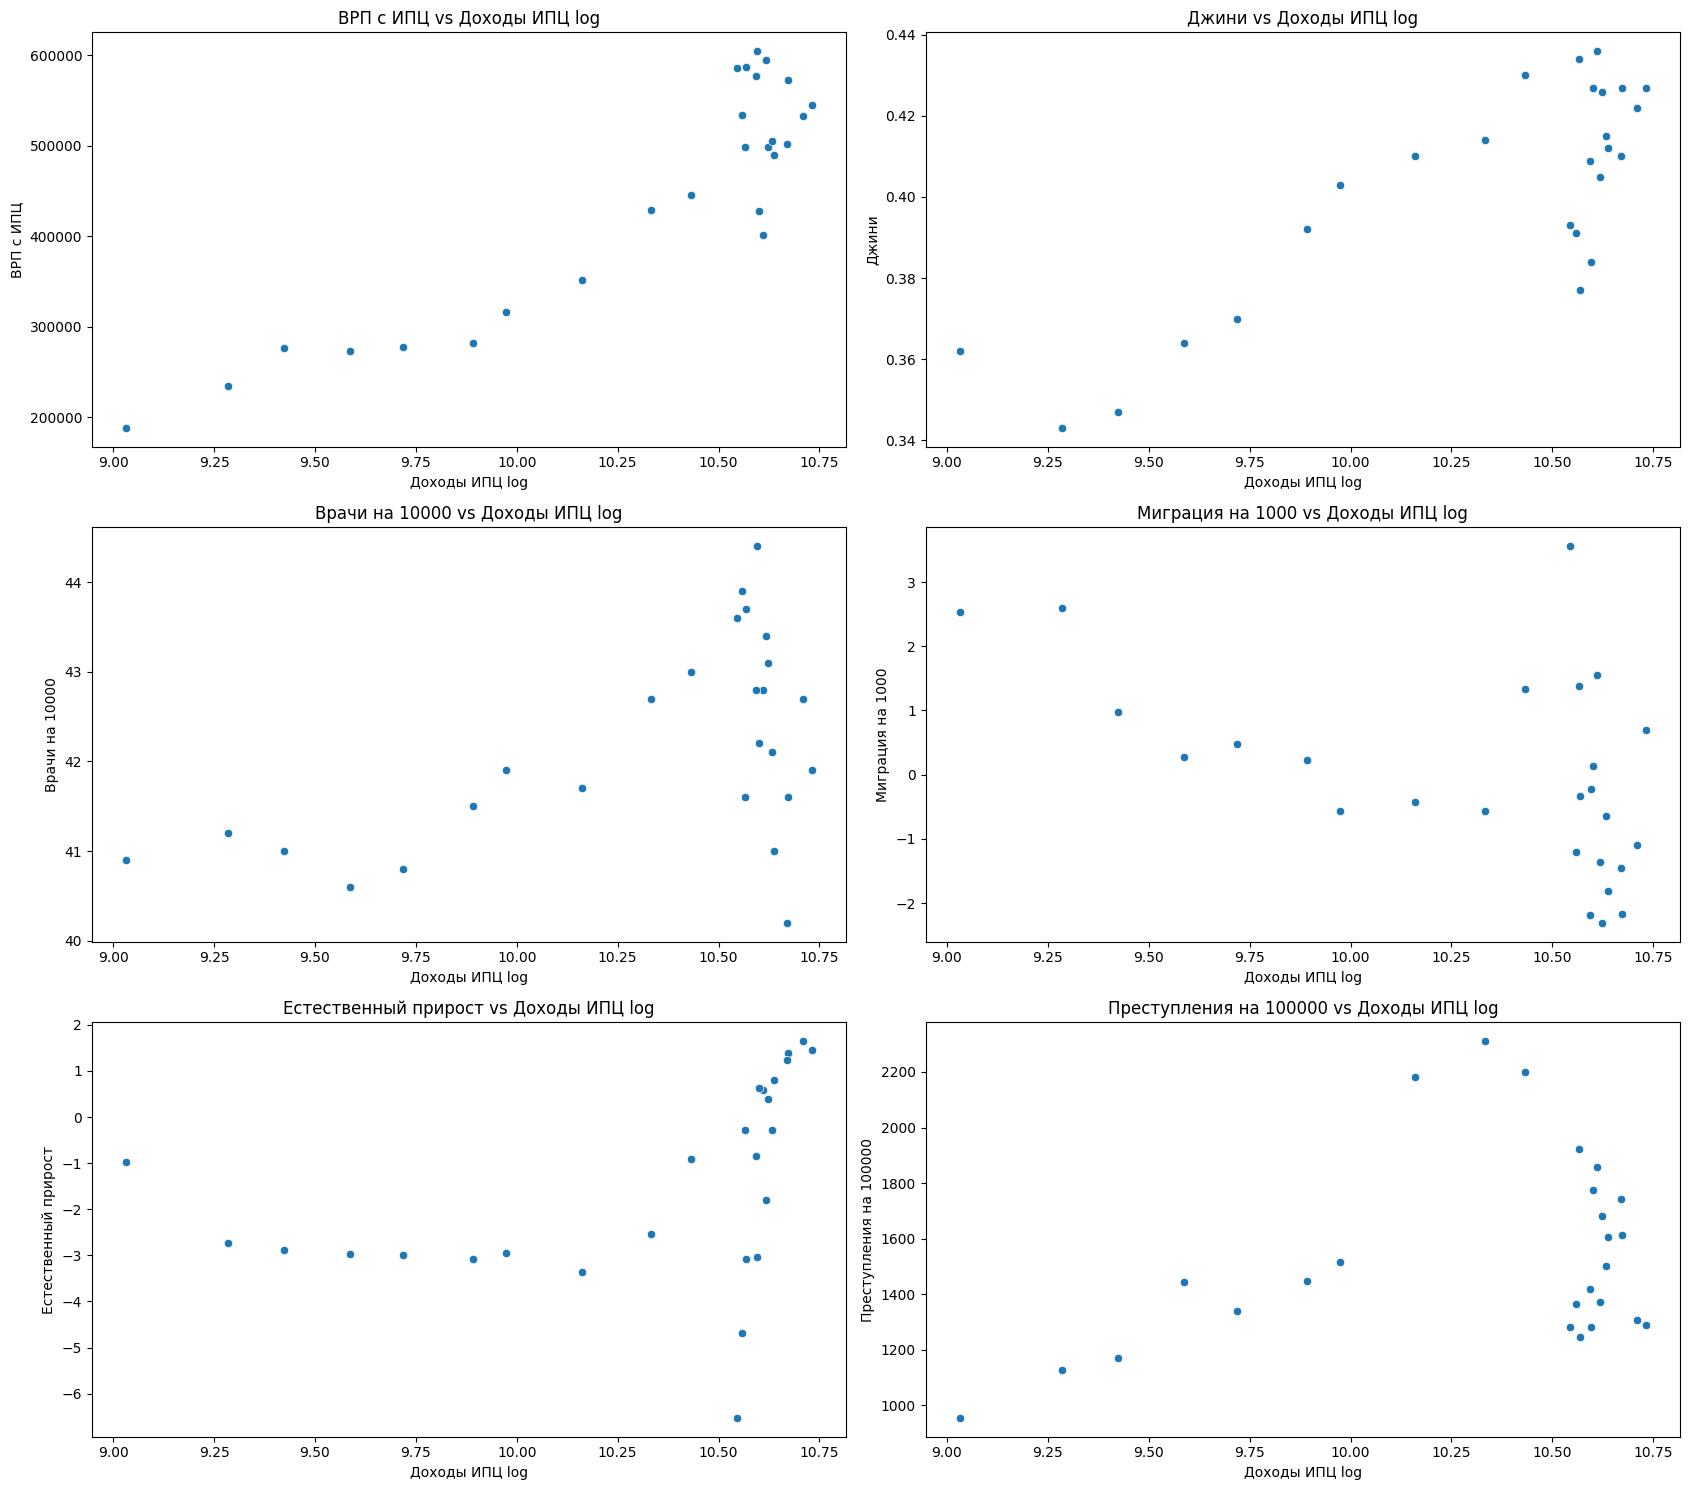

In [119]:
target = 'Доходы ИПЦ log'
features = [col for col in df.columns if col != target]

n_features = len(features)
n_cols = 2  # число столбцов подграфиков
n_rows = (n_features + n_cols - 1) // n_cols  # автоматически считаем число строк

fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 5 * n_rows))
axes = axes.flatten()  # делаем список из массива осей

for i, col in enumerate(features):
    sns.scatterplot(x=df[target], y=df[col], ax=axes[i])
    axes[i].set_title(f'{col} vs {target}')
    axes[i].set_xlabel(target)
    axes[i].set_ylabel(col)

# Удалим пустые подграфики, если они остались
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [120]:
from itertools import combinations

# Список независимых переменных
features = ['grp', 'doctors', 'gini', 'migration', 'naturalpopulationgrowth', 'students']

# Генерация всех комбинаций от 1 до len(features)
all_combinations = []
for r in range(1, len(features)+1):
    combos = list(combinations(features, r))
    all_combinations.extend(combos)

# Вывод комбинаций
for i, combo in enumerate(all_combinations, 1):
    print(f"{i}. {combo}")

1. ('grp',)
2. ('doctors',)
3. ('gini',)
4. ('migration',)
5. ('naturalpopulationgrowth',)
6. ('students',)
7. ('grp', 'doctors')
8. ('grp', 'gini')
9. ('grp', 'migration')
10. ('grp', 'naturalpopulationgrowth')
11. ('grp', 'students')
12. ('doctors', 'gini')
13. ('doctors', 'migration')
14. ('doctors', 'naturalpopulationgrowth')
15. ('doctors', 'students')
16. ('gini', 'migration')
17. ('gini', 'naturalpopulationgrowth')
18. ('gini', 'students')
19. ('migration', 'naturalpopulationgrowth')
20. ('migration', 'students')
21. ('naturalpopulationgrowth', 'students')
22. ('grp', 'doctors', 'gini')
23. ('grp', 'doctors', 'migration')
24. ('grp', 'doctors', 'naturalpopulationgrowth')
25. ('grp', 'doctors', 'students')
26. ('grp', 'gini', 'migration')
27. ('grp', 'gini', 'naturalpopulationgrowth')
28. ('grp', 'gini', 'students')
29. ('grp', 'migration', 'naturalpopulationgrowth')
30. ('grp', 'migration', 'students')
31. ('grp', 'naturalpopulationgrowth', 'students')
32. ('doctors', 'gini', 'm